# 365 Real Estate — Dubai Residential Price Prediction
**Regression | Linear Regression vs log-price Linear Regression**

The notebook uses the supplied DLD CSV only. The filters below operationalise residential sales and should be checked against the actual distinct values and your instructor's intended population.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import joblib, warnings
warnings.filterwarnings('ignore')
DATA_PATH='dld_transactions.csv'
raw=pd.read_csv(DATA_PATH,low_memory=False)

## 1. Original data profile

In [2]:
print('Shape:',raw.shape)
print('Data types:\n',raw.dtypes)
print('Missing values:\n',raw.isna().sum().sort_values(ascending=False).head(20))
print('Exact duplicate rows:',raw.duplicated().sum())
for c in ['trans_group_en','property_usage_en','property_type_en','property_sub_type_en','reg_type_en','procedure_name_en']:
 print('\n',c,raw[c].value_counts(dropna=False).head(20))

Shape: (172704, 34)
Data types:
 transaction_id           object
procedure_id              int64
trans_group_id            int64
trans_group_en           object
trans_group_ar           object
procedure_name_en        object
instance_date            object
property_type_en         object
property_type_ar         object
property_sub_type_en     object
property_usage_en        object
property_usage_ar        object
reg_type_en              object
reg_type_ar              object
area_id                   int64
area_name_en             object
area_name_ar             object
building_name_en         object
project_name_en          object
master_project_en        object
nearest_landmark_en      object
nearest_metro_en         object
nearest_mall_en          object
rooms_en                 object
rooms_ar                 object
has_parking               int64
procedure_area          float64
actual_worth            float64
meter_sale_price        float64
rent_value              float64
meter_r

Exact duplicate rows: 4704

 trans_group_en trans_group_en
Sales        113458
Mortgages     46677
Gifts         12569
Name: count, dtype: int64

 property_usage_en property_usage_en
Residential    145967
Commercial      26737
Name: count, dtype: int64

 property_type_en property_type_en
Unit        144450
Villa        19606
Land          5039
Building      3609
Name: count, dtype: int64

 property_sub_type_en property_sub_type_en
Flat                        124328
Villa                        19606
Office                       10100
Shop                          7173
Residential Land              5039
Residential / Commercial      3609
Hotel Apartment               2849
Name: count, dtype: int64

 reg_type_en reg_type_en
Existing Properties    96748
Off-Plan Properties    75956
Name: count, dtype: int64

 procedure_name_en procedure_name_en
Sell                     63423
Sell Pre-Registration    50035
Mortgage Registration    46677
Grant                    12569
Name: count, dtype: in

## 2. Filter to residential sales and validate sizes/prices
Filters: trans_group_en is Sales; property_usage_en is Residential; positive actual_worth and procedure_area; remove implausibly tiny area below 10 m². We retain high prices unless inspection shows they are errors, because luxury properties can be genuine.

In [3]:
df=raw.copy()
df['instance_date']=pd.to_datetime(df['instance_date'],dayfirst=True,errors='coerce')
for c in ['actual_worth','procedure_area','meter_sale_price','has_parking']:
 df[c]=pd.to_numeric(df[c],errors='coerce')
print('Original rows:',len(df))
df=df[df['trans_group_en'].astype(str).str.strip().str.lower().eq('sales')]; print('After Sales filter:',len(df))
df=df[df['property_usage_en'].astype(str).str.strip().str.lower().eq('residential')]; print('After Residential filter:',len(df))
df=df[df['actual_worth'].gt(0) & df['procedure_area'].ge(10)]; print('After positive price and area >=10 sqm:',len(df))
print('Price quantiles:\n',df['actual_worth'].quantile([0,.01,.25,.5,.75,.95,.99,1]))
print('Area quantiles sqm:\n',df['procedure_area'].quantile([0,.01,.25,.5,.75,.95,.99,1]))
df['area_sqft']=df['procedure_area']*10.7639
df['price_per_sqft']=df['actual_worth']/df['area_sqft']
df['area_name_en']=df['area_name_en'].astype('string').str.strip().str.replace(r'\s+',' ',regex=True)
df['sale_year']=df['instance_date'].dt.year; df['sale_month']=df['instance_date'].dt.month
print('Final filtered shape:',df.shape,'date range:',df.instance_date.min(),df.instance_date.max())
display(df.head())

Original rows: 172704
After Sales filter: 113458
After Residential filter: 95845
After positive price and area >=10 sqm: 95586
Price quantiles:
 0.00    1.514824e+05
0.01    3.422588e+05
0.25    9.393269e+05
0.50    1.554230e+06
0.75    2.750140e+06
0.95    9.044311e+06
0.99    3.401123e+07
1.00    6.461994e+08
Name: actual_worth, dtype: float64
Area quantiles sqm:
 0.00       35.3100
0.01       36.7385
0.25       68.2400
0.50      104.1600
0.75      177.4075
0.95      673.3600
0.99     2814.1490
1.00    31103.5300
Name: procedure_area, dtype: float64


Final filtered shape: (95586, 38) date range: 2020-01-01 00:00:00 2025-12-31 00:00:00


,transaction_id,procedure_id,trans_group_id,trans_group_en,trans_group_ar,procedure_name_en,instance_date,property_type_en,property_type_ar,property_sub_type_en,property_usage_en,property_usage_ar,reg_type_en,reg_type_ar,area_id,area_name_en,area_name_ar,building_name_en,project_name_en,master_project_en,nearest_landmark_en,nearest_metro_en,nearest_mall_en,rooms_en,rooms_ar,has_parking,procedure_area,actual_worth,meter_sale_price,rent_value,meter_rent_price,no_of_parties_role_1,no_of_parties_role_2,no_of_parties_role_3,area_sqft,price_per_sqft,sale_year,sale_month
2,86629276-116-2024,11,1,Sales,مبايعات,Sell,2024-10-14,Unit,وحدة,Flat,Residential,سكني,Existing Properties,عقارات جاهزة,353,Al Safouh First,الصفوح الأولى,THE PALM TOWER,THE PALM TOWER,PALM JUMEIRAH,Burj Al Arab,NaN,Mall of the Emirates,1 B/R,غرفة واحدة,1,86.18,1965098.59,22802.26,NaN,NaN,1,1,1,927.632902,2118.401132,2024,10
3,43565509-159-2021,11,1,Sales,مبايعات,Sell Pre-Registration,2021-09-19,Unit,وحدة,Flat,Residential,سكني,Off-Plan Properties,عقارات على الخارطة,368,Palm Jumeirah,نخلة جميرا,SERENIA RESIDENCES,SERENIA RESIDENCES,PALM JUMEIRAH,Burj Al Arab,Nakheel,Nakheel Mall,Studio,استوديو,1,47.13,1124967.29,23869.45,NaN,NaN,2,1,1,507.302607,2217.546834,2021,9
5,28961253-154-2021,11,1,Sales,مبايعات,Sell Pre-Registration,2021-03-21,Unit,وحدة,Flat,Residential,سكني,Off-Plan Properties,عقارات على الخارطة,372,Al Merkadh,المركاض,DISTRICT ONE VILLAS TOWER 1,DISTRICT ONE VILLAS,NaN,Downtown Dubai,Creek,Dubai Mall,3 B/R,ثلاث غرف,1,141.64,1842609.29,13009.10,NaN,NaN,1,1,0,1524.598796,1208.586347,2021,3
7,55967915-249-2023,11,1,Sales,مبايعات,Sell,2023-01-11,Unit,وحدة,Flat,Residential,سكني,Existing Properties,عقارات جاهزة,367,Business Bay,الخليج التجاري,MERANO TOWER,MERANO TOWER,NaN,NaN,NaN,Dubai Mall,2 B/R,غرفتين,1,131.32,2426390.35,18476.93,NaN,NaN,2,1,0,1413.515348,1716.564559,2023,1
8,37088223-2-2023,11,1,Sales,مبايعات,Sell Pre-Registration,2023-01-30,Unit,وحدة,Flat,Residential,سكني,Off-Plan Properties,عقارات على الخارطة,673,Al Hebiah Fourth,الحبية الرابعة,CARSON THE DRIVE,CARSON THE DRIVE,DAMAC HILLS,Motor City,Mall of the Emirates,NaN,2 B/R,غرفتين,1,94.45,1082081.79,11456.66,NaN,NaN,2,1,1,1016.650355,1064.359821,2023,1


## 3. Exploratory market analysis (eight charts)

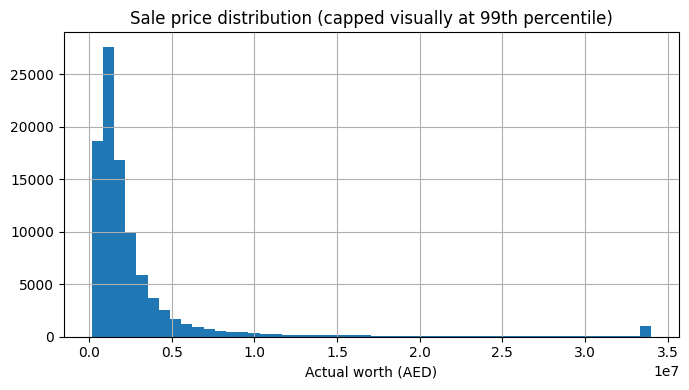

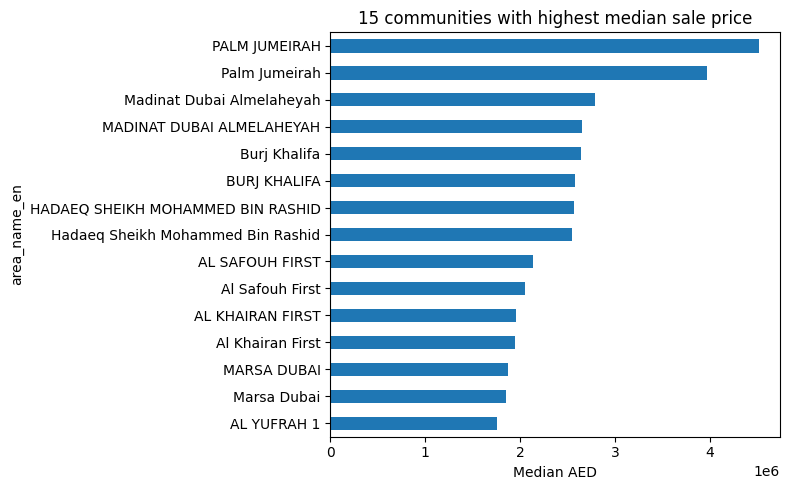

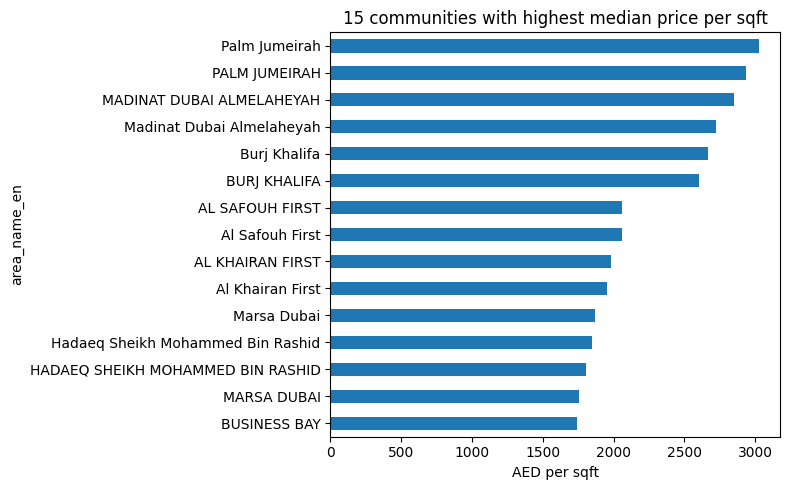

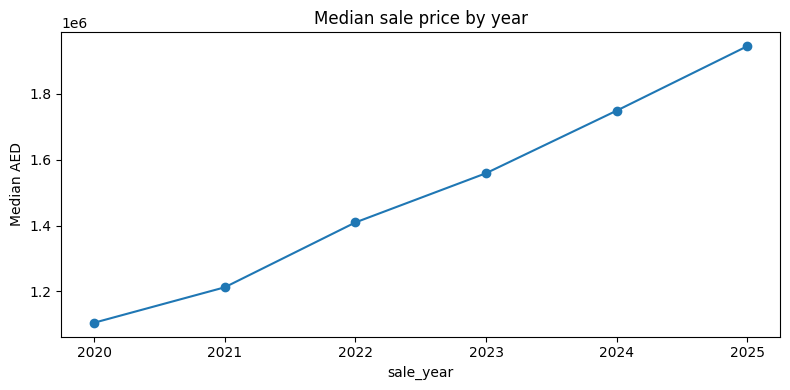

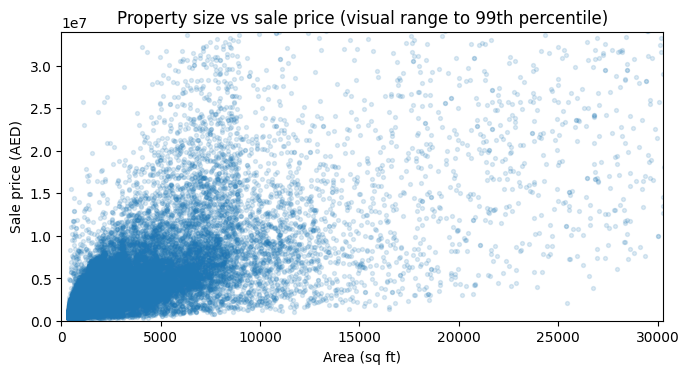

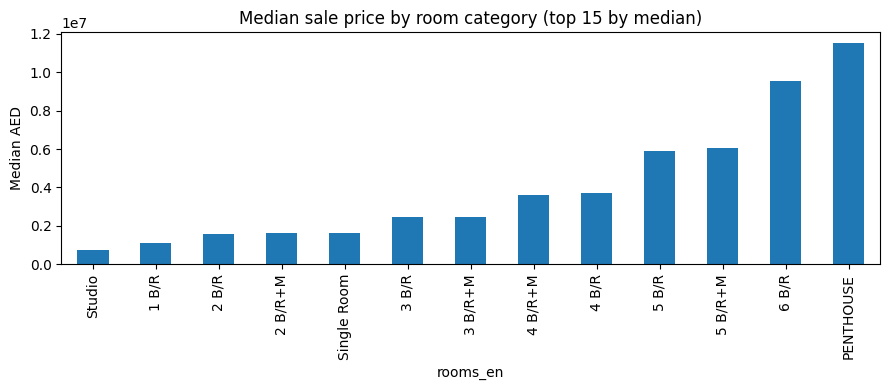

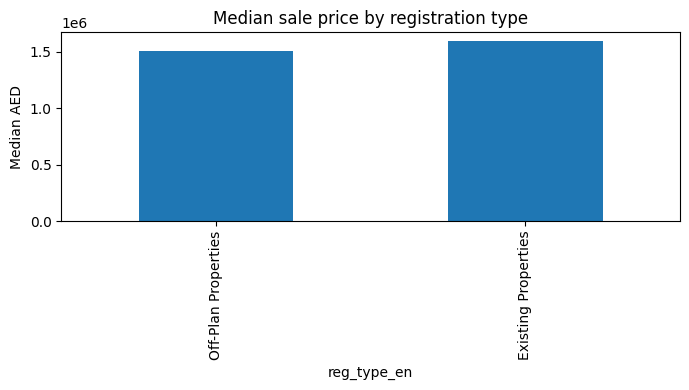

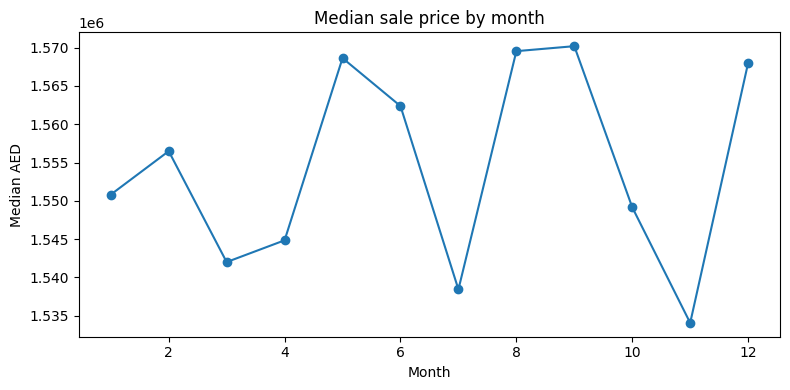

In [4]:
fig,ax=plt.subplots(figsize=(7,4)); df['actual_worth'].clip(upper=df['actual_worth'].quantile(.99)).hist(bins=50,ax=ax); ax.set_title('Sale price distribution (capped visually at 99th percentile)'); ax.set_xlabel('Actual worth (AED)'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(8,5)); df.groupby('area_name_en')['actual_worth'].median().nlargest(15).sort_values().plot(kind='barh',ax=ax); ax.set_title('15 communities with highest median sale price'); ax.set_xlabel('Median AED'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(8,5)); df.groupby('area_name_en')['price_per_sqft'].median().nlargest(15).sort_values().plot(kind='barh',ax=ax); ax.set_title('15 communities with highest median price per sqft'); ax.set_xlabel('AED per sqft'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); df.groupby('sale_year')['actual_worth'].median().plot(marker='o',ax=ax); ax.set_title('Median sale price by year'); ax.set_ylabel('Median AED'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(7,4)); ax.scatter(df['area_sqft'],df['actual_worth'],alpha=.15,s=8); ax.set_xlim(0,df.area_sqft.quantile(.99)); ax.set_ylim(0,df.actual_worth.quantile(.99)); ax.set_title('Property size vs sale price (visual range to 99th percentile)'); ax.set_xlabel('Area (sq ft)'); ax.set_ylabel('Sale price (AED)'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(9,4)); df.groupby('rooms_en')['actual_worth'].median().sort_values().tail(15).plot(kind='bar',ax=ax); ax.set_title('Median sale price by room category (top 15 by median)'); ax.set_ylabel('Median AED'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(7,4)); df.groupby('reg_type_en')['actual_worth'].median().sort_values().plot(kind='bar',ax=ax); ax.set_title('Median sale price by registration type'); ax.set_ylabel('Median AED'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); df.groupby('sale_month')['actual_worth'].median().plot(marker='o',ax=ax); ax.set_title('Median sale price by month'); ax.set_xlabel('Month'); ax.set_ylabel('Median AED'); plt.tight_layout(); plt.show()

## 4. Feature engineering and leakage review
Exclude transaction IDs, actual_worth target, meter_sale_price (derived from sale price and area), rent fields, Arabic duplicates, and post-sale/administrative fields not appropriate for pre-close valuation. Convert square metres to square feet. One-hot encode categorical variables.

In [5]:
numeric=['area_sqft','has_parking','sale_year','sale_month']
categorical=[c for c in ['area_name_en','property_type_en','property_sub_type_en','rooms_en','reg_type_en','master_project_en'] if c in df.columns]
features=numeric+categorical
model_df=df.dropna(subset=['actual_worth']).copy()
# Restrict target to positive values for log target; this is already ensured by filtering.
X=model_df[features].copy(); y=model_df['actual_worth'].astype(float)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
pre=ColumnTransformer([('num',Pipeline([('imputer',SimpleImputer(strategy='median'))]),numeric),('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore',min_frequency=10))]),categorical)])

## 5. Fit raw-price and log-price Linear Regression models

In [6]:
raw_model=Pipeline([('prep',pre),('reg',LinearRegression())])
log_model=Pipeline([('prep',pre),('reg',LinearRegression())])
raw_model.fit(X_train,y_train)
log_model.fit(X_train,np.log(y_train))
pred_raw=np.maximum(0,raw_model.predict(X_test))
pred_log=np.maximum(0,np.exp(log_model.predict(X_test)))
def score(y,p):
 return {'R2':r2_score(y,p),'MAE_AED':mean_absolute_error(y,p),'RMSE_AED':mean_squared_error(y,p)**.5,'MAPE_percent':np.mean(np.abs((np.asarray(y)-p)/np.asarray(y)))*100}
results=pd.DataFrame({'Raw-price Linear Regression':score(y_test,pred_raw),'Log-price Linear Regression':score(y_test,pred_log)}).T
display(results.round(3))
chosen=log_model if results.loc['Log-price Linear Regression','MAE_AED'] < results.loc['Raw-price Linear Regression','MAE_AED'] else raw_model
chosen_pred=pred_log if chosen is log_model else pred_raw
print('Selected by lower MAE on held-out test set:', 'log-price' if chosen is log_model else 'raw-price')

,R2,MAE_AED,RMSE_AED,MAPE_percent
Raw-price Linear Regression,0.761,1125998.802,3866780.706,45.789
Log-price Linear Regression,0.235,810927.147,6917088.303,20.381


Selected by lower MAE on held-out test set: log-price


## 6. Error analysis and actual vs predicted

Error by price band:


,n,MAE
price_band,,
"(176163.779, 931129.525]",4780,1.442413e+05
"(931129.525, 1536792.5]",4779,2.204365e+05
"(1536792.5, 2748608.22]",4779,3.664197e+05
"(2748608.22, 265406177.32]",4780,2.512395e+06


Error by room category (top groups by sample size):


,n,MAE
rooms,,
1 B/R,5034,2.213676e+05
2 B/R,4195,3.323155e+05
Studio,2781,1.626890e+05
3 B/R,2697,5.400629e+05
4 B/R,1313,8.395034e+05
5 B/R,456,1.791237e+06
PENTHOUSE,317,3.922123e+06
6 B/R,218,2.237240e+06
2 B/R+M,178,3.869076e+05


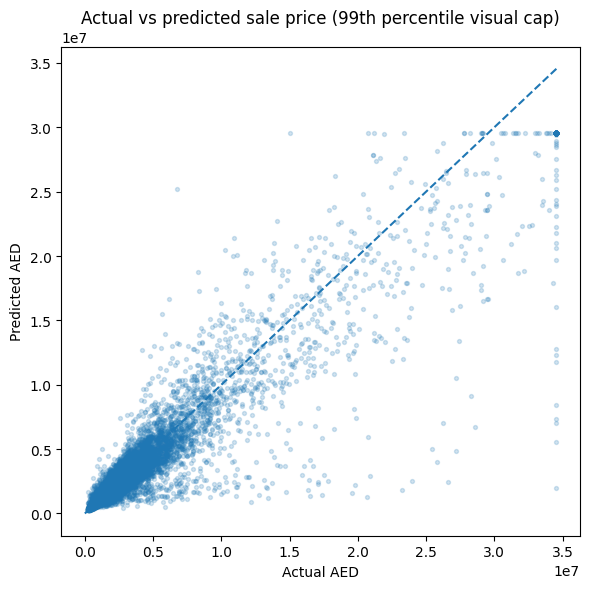

In [7]:
err=pd.DataFrame({'actual':y_test,'predicted':chosen_pred,'abs_error':np.abs(y_test-chosen_pred),'community':model_df.loc[y_test.index,'area_name_en'].values,'rooms':model_df.loc[y_test.index,'rooms_en'].values})
err['price_band']=pd.qcut(err.actual,4,duplicates='drop')
print('Error by price band:'); display(err.groupby('price_band',observed=False).agg(n=('actual','size'),MAE=('abs_error','mean')))
print('Error by room category (top groups by sample size):'); display(err.groupby('rooms').agg(n=('actual','size'),MAE=('abs_error','mean')).query('n >= 30').sort_values('n',ascending=False).head(15))
fig,ax=plt.subplots(figsize=(6,6)); ax.scatter(err.actual.clip(upper=err.actual.quantile(.99)),err.predicted.clip(upper=err.predicted.quantile(.99)),alpha=.2,s=8); lim=max(err.actual.quantile(.99),err.predicted.quantile(.99)); ax.plot([0,lim],[0,lim],linestyle='--'); ax.set_title('Actual vs predicted sale price (99th percentile visual cap)'); ax.set_xlabel('Actual AED'); ax.set_ylabel('Predicted AED'); plt.tight_layout(); plt.show()

## 7. Business recommendations and limitations
Use the model as a first-pass valuation aid, not as a replacement for a valuer. Review high-value and unusual properties manually, use same-community comparables, and monitor errors by community and property type. The log model can reduce the influence of the long right tail, but compare AED-based test metrics before selecting it. Historical associations are not causal. The dataset lacks property condition, view, floor, precise micro-location and negotiation context.

In [8]:
model_df.to_csv('real_estate_model_dataset.csv',index=False)
joblib.dump(chosen,'real_estate_valuation_model.joblib')
print('Saved real_estate_model_dataset.csv and real_estate_valuation_model.joblib')

Saved real_estate_model_dataset.csv and real_estate_valuation_model.joblib
